In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
import pandas as pd
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)
tokenised_df=pd.read_csv("hugging_tokenised_df.csv")
untokenised_df=pd.read_csv("hugging_untokenised.csv")
validation_df=pd.read_csv('no_duplicate_validation.csv')
emotion=pd.read_csv('emotion_label_hugging.csv')

# TF IDF

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [52]:
def tfidf(data):
    tf=TfidfVectorizer()
    x_train=tf.fit_transform(data)
    return x_train,tf

In [53]:
tfid_x_train,tf=tfidf(untokenised_df["text"])
y_train=untokenised_df["label"]

In [54]:
print(tfid_x_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 156288 stored elements and shape (15999, 12143)>
  Coords	Values
  (0, 7404)	0.28566244828769194
  (0, 4029)	0.12423762815659936
  (0, 5291)	0.9502431148860297
  (1, 4029)	0.05823951547929917
  (1, 1634)	0.19424501938294764
  (1, 4636)	0.20581957698359848
  (1, 9883)	0.3203699873335642
  (1, 5221)	0.3536212614501394
  (1, 2680)	0.49303513473551724
  (1, 5219)	0.35797185959062694
  (1, 11846)	0.23915240812507368
  (1, 1691)	0.3004144240240566
  (1, 905)	0.4125048010170097
  (2, 4029)	0.07303371947888167
  (2, 4680)	0.5389966736542179
  (2, 6887)	0.4477784689355859
  (2, 8264)	0.3747847130291185
  (2, 4728)	0.44557955194696147
  (2, 12022)	0.40575656018467204
  (3, 4029)	0.06257919061701503
  (3, 3763)	0.31065161063283225
  (3, 7401)	0.39300347233985994
  (3, 4130)	0.5428056689958927
  (3, 11882)	0.23903377578950272
  (3, 6056)	0.22241339989163844
  :	:
  (15995, 11122)	0.2847062062272555
  (15995, 11674)	0.29430904493248417
 

In [55]:
print(y_train)

0        0
1        0
2        3
3        2
4        3
        ..
15994    0
15995    0
15996    1
15997    3
15998    0
Name: label, Length: 15999, dtype: int64


In [56]:
print(tf)

TfidfVectorizer()


In [57]:
print(tf.get_feature_names_out())

['aa' 'aaaaaaand' 'aaaaand' ... 'zum' 'zumba' 'zz']


In [58]:
x_val_text=validation_df["text"]
y_val_label=validation_df["label"]

In [59]:
x_val=tf.transform(x_val_text)

# TRAINING

In [60]:
def train(model):
    return model.fit(tfid_x_train,y_train)
    

# METRIC FUNCTION

In [61]:
def Metric(y_val,y_pred):
    accuracy=accuracy_score(y_val,y_pred)
    print("Accuracy=",accuracy)
    precision=precision_score(y_val,y_pred,average="weighted")
    print("precision=",precision)
    recall=recall_score(y_val,y_pred,average="weighted")
    print("recall=",recall)
    f1=f1_score(y_val,y_pred,average="weighted")
    print("F1 score=",f1)
    macro_f1=f1_score(y_val,y_pred,average="macro")
    print("macro F1 Score=",macro_f1)
    cm=confusion_matrix(y_val,y_pred)
    print("Confusion Matrix:")
    print(cm)
    cr=classification_report(y_val,y_pred)
    print("classification Report:")
    print(cr)

# Naive bayes

In [62]:
from sklearn.naive_bayes import MultinomialNB
naive_bayes_model=MultinomialNB()
train(naive_bayes_model)
print(naive_bayes_model)

MultinomialNB()


In [63]:
y_train_nb_pred=naive_bayes_model.predict(tfid_x_train)

## validation

In [64]:
y_val_nb=naive_bayes_model.predict(x_val)

In [65]:
print(y_val_nb)

[0 0 1 ... 1 1 1]


## Metrics accuracy

In [66]:
Metric(y_train,y_train_nb_pred)

Accuracy= 0.7356709794362147
precision= 0.8043474991558164
recall= 0.7356709794362147
F1 score= 0.6862201745689137
macro F1 Score= 0.515973865740804
Confusion Matrix:
[[4495  168    0    1    2    0]
 [  65 5294    0    0    2    0]
 [ 189  946  164    4    1    0]
 [ 585  538    0 1029    7    0]
 [ 547  587    0   24  779    0]
 [ 203  329    0    0   31    9]]
classification Report:
              precision    recall  f1-score   support

           0       0.74      0.96      0.84      4666
           1       0.67      0.99      0.80      5361
           2       1.00      0.13      0.22      1304
           3       0.97      0.48      0.64      2159
           4       0.95      0.40      0.56      1937
           5       1.00      0.02      0.03       572

    accuracy                           0.74     15999
   macro avg       0.89      0.50      0.52     15999
weighted avg       0.80      0.74      0.69     15999



In [67]:
Metric(y_val_label,y_val_nb)

Accuracy= 0.6472945891783567
precision= 0.7580038019207488
recall= 0.6472945891783567
F1 score= 0.5737658218888658
macro F1 Score= 0.39576630852550343
Confusion Matrix:
[[506  44   0   0   0   0]
 [ 49 654   0   0   0   0]
 [ 58 113   6   0   0   0]
 [115  79   0  80   0   0]
 [ 90  76   0   0  45   0]
 [ 45  32   0   0   3   1]]
classification Report:
              precision    recall  f1-score   support

           0       0.59      0.92      0.72       550
           1       0.66      0.93      0.77       703
           2       1.00      0.03      0.07       177
           3       1.00      0.29      0.45       274
           4       0.94      0.21      0.35       211
           5       1.00      0.01      0.02        81

    accuracy                           0.65      1996
   macro avg       0.86      0.40      0.40      1996
weighted avg       0.76      0.65      0.57      1996



# Logistic Regression

In [68]:
from sklearn.linear_model import LogisticRegression
logistic_regression_model=LogisticRegression(C=0.4,class_weight='balanced',random_state=42,max_iter=1000)
train(logistic_regression_model)
print(logistic_regression_model)



LogisticRegression(C=0.4, class_weight='balanced', max_iter=1000,
                   random_state=42)


In [69]:
y_train_lg_pred=logistic_regression_model.predict(tfid_x_train)

## Validation

In [70]:
y_pred_lg=logistic_regression_model.predict(x_val)

In [71]:
print(y_pred_lg)

[0 0 2 ... 1 2 1]


## Metrics

In [72]:
Metric(y_train,y_train_lg_pred)

Accuracy= 0.9031189449340584
precision= 0.9146632344397845
recall= 0.9031189449340584
F1 score= 0.9052093181548573
macro F1 Score= 0.8837837796701377
Confusion Matrix:
[[4161  127   91  143  106   38]
 [ 119 4684  375   62   43   78]
 [   2   19 1269    7    4    3]
 [  34   28   22 2039   29    7]
 [  15   19   20   46 1727  110]
 [   0    0    1    0    2  569]]
classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      4666
           1       0.96      0.87      0.92      5361
           2       0.71      0.97      0.82      1304
           3       0.89      0.94      0.92      2159
           4       0.90      0.89      0.90      1937
           5       0.71      0.99      0.83       572

    accuracy                           0.90     15999
   macro avg       0.86      0.93      0.88     15999
weighted avg       0.91      0.90      0.91     15999



In [73]:
Metric(y_val_label,y_pred_lg)

Accuracy= 0.8156312625250501
precision= 0.8206800589717396
recall= 0.8156312625250501
F1 score= 0.8166433954256418
macro F1 Score= 0.7820508455442138
Confusion Matrix:
[[452  33  14  28  16   7]
 [ 35 591  45  15   6  11]
 [ 14  15 141   4   2   1]
 [ 16  15   4 234   4   1]
 [ 18  15   3   9 148  18]
 [  8   8   0   1   2  62]]
classification Report:
              precision    recall  f1-score   support

           0       0.83      0.82      0.83       550
           1       0.87      0.84      0.86       703
           2       0.68      0.80      0.73       177
           3       0.80      0.85      0.83       274
           4       0.83      0.70      0.76       211
           5       0.62      0.77      0.69        81

    accuracy                           0.82      1996
   macro avg       0.77      0.80      0.78      1996
weighted avg       0.82      0.82      0.82      1996



# Support Vector Machine

In [74]:
from sklearn.svm import SVC
svm_model=SVC()
train(svm_model)
print(svm_model)

SVC()


In [75]:
y_train_svm_pred=svm_model.predict(tfid_x_train)

## validation

In [76]:
y_pred_svm=svm_model.predict(x_val)

In [77]:
print(y_pred_svm)

[0 0 2 ... 1 1 1]


## Metrics

In [78]:
Metric(y_train,y_train_svm_pred)

Accuracy= 0.9868741796362273
precision= 0.9869040123811698
recall= 0.9868741796362273
F1 score= 0.9868214904161453
macro F1 Score= 0.9817756711387711
Confusion Matrix:
[[4638    6    2   11    7    2]
 [   9 5338    7    2    5    0]
 [   2   64 1237    1    0    0]
 [  27    1    0 2126    5    0]
 [   9    3    1   13 1907    4]
 [   3   13    0    0   13  543]]
classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4666
           1       0.98      1.00      0.99      5361
           2       0.99      0.95      0.97      1304
           3       0.99      0.98      0.99      2159
           4       0.98      0.98      0.98      1937
           5       0.99      0.95      0.97       572

    accuracy                           0.99     15999
   macro avg       0.99      0.98      0.98     15999
weighted avg       0.99      0.99      0.99     15999



In [79]:
Metric(y_val_label,y_pred_svm)

Accuracy= 0.7865731462925851
precision= 0.8044374451519679
recall= 0.7865731462925851
F1 score= 0.774643795833204
macro F1 Score= 0.7114340919195029
Confusion Matrix:
[[480  48   1  10  10   1]
 [ 24 668   5   4   1   1]
 [ 24  76  73   2   2   0]
 [ 39  49   1 183   2   0]
 [ 26  43   1   6 133   2]
 [ 17  21   0   0  10  33]]
classification Report:
              precision    recall  f1-score   support

           0       0.79      0.87      0.83       550
           1       0.74      0.95      0.83       703
           2       0.90      0.41      0.57       177
           3       0.89      0.67      0.76       274
           4       0.84      0.63      0.72       211
           5       0.89      0.41      0.56        81

    accuracy                           0.79      1996
   macro avg       0.84      0.66      0.71      1996
weighted avg       0.80      0.79      0.77      1996



# Random Forest

In [80]:
from sklearn.ensemble import RandomForestClassifier
random_forest_model=RandomForestClassifier()
train(random_forest_model)
print(random_forest_model)

RandomForestClassifier()


In [81]:
y_train_rf_pred=random_forest_model.predict(tfid_x_train)

## Validation

In [82]:
y_pred_rf=random_forest_model.predict(x_val)

In [83]:
print(y_pred_rf)

[0 0 2 ... 1 1 1]


### 

##  Metrics

In [84]:
Metric(y_train,y_train_rf_pred)

Accuracy= 0.9977498593662104
precision= 0.9977495260670134
recall= 0.9977498593662104
F1 score= 0.9977487790969636
macro F1 Score= 0.996215429300873
Confusion Matrix:
[[4662    0    0    3    1    0]
 [   0 5357    4    0    0    0]
 [   0   11 1293    0    0    0]
 [   2    0    0 2156    1    0]
 [   1    0    0    3 1928    5]
 [   0    1    0    0    4  567]]
classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4666
           1       1.00      1.00      1.00      5361
           2       1.00      0.99      0.99      1304
           3       1.00      1.00      1.00      2159
           4       1.00      1.00      1.00      1937
           5       0.99      0.99      0.99       572

    accuracy                           1.00     15999
   macro avg       1.00      1.00      1.00     15999
weighted avg       1.00      1.00      1.00     15999



In [85]:
Metric(y_val_label,y_pred_rf)

Accuracy= 0.7950901803607214
precision= 0.8024435417103385
recall= 0.7950901803607214
F1 score= 0.7919825776679728
macro F1 Score= 0.7595306461510504
Confusion Matrix:
[[429  90   6  13  10   2]
 [ 33 645   9  10   5   1]
 [ 10  51 108   5   2   1]
 [ 16  41   1 210   6   0]
 [ 21  22   0   9 150   9]
 [  9  16   0   1  10  45]]
classification Report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       550
           1       0.75      0.92      0.82       703
           2       0.87      0.61      0.72       177
           3       0.85      0.77      0.80       274
           4       0.82      0.71      0.76       211
           5       0.78      0.56      0.65        81

    accuracy                           0.80      1996
   macro avg       0.81      0.72      0.76      1996
weighted avg       0.80      0.80      0.79      1996



# XGBOOST

In [86]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [87]:
from xgboost import XGBClassifier

In [88]:
xgb_model=XGBClassifier(objective='multi:softmax',num_class=len(y_train.unique()),n_estimators=100,learning_rate=0.1,max_depth=6,random_state=42,
                        eval_metric='mlogloss')
train(xgb_model)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [89]:
print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, num_class=6, ...)


In [90]:
y_train_xg_pred=xgb_model.predict(tfid_x_train)

## Validation

In [91]:
y_pred_xg=xgb_model.predict(x_val)

In [92]:
print(y_pred_xg)

[0 0 2 ... 1 2 1]


## Metric

In [93]:
Metric(y_train,y_train_xg_pred)

Accuracy= 0.8657416088505532
precision= 0.8817036987808939
recall= 0.8657416088505532
F1 score= 0.8664204214873552
macro F1 Score= 0.8592722034075332
Confusion Matrix:
[[3877  698   11   41   23   16]
 [  32 5185   98   14   17   15]
 [  14  335  944    3    6    2]
 [  57  336    3 1741   21    1]
 [  51  192    4   26 1600   64]
 [   2   28    2    1   35  504]]
classification Report:
              precision    recall  f1-score   support

           0       0.96      0.83      0.89      4666
           1       0.77      0.97      0.85      5361
           2       0.89      0.72      0.80      1304
           3       0.95      0.81      0.87      2159
           4       0.94      0.83      0.88      1937
           5       0.84      0.88      0.86       572

    accuracy                           0.87     15999
   macro avg       0.89      0.84      0.86     15999
weighted avg       0.88      0.87      0.87     15999



In [94]:
Metric(y_val_label,y_pred_xg)

Accuracy= 0.7449899799599199
precision= 0.7906667948628392
recall= 0.7449899799599199
F1 score= 0.7439188583673236
macro F1 Score= 0.7308528086461205
Confusion Matrix:
[[348 171   4  12  10   5]
 [ 10 661  18   4   4   6]
 [  3  60 110   2   1   1]
 [  4  86   0 181   2   1]
 [ 13  52   0   2 131  13]
 [  1  19   0   1   4  56]]
classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75       550
           1       0.63      0.94      0.75       703
           2       0.83      0.62      0.71       177
           3       0.90      0.66      0.76       274
           4       0.86      0.62      0.72       211
           5       0.68      0.69      0.69        81

    accuracy                           0.74      1996
   macro avg       0.80      0.69      0.73      1996
weighted avg       0.79      0.74      0.74      1996



# Compare Metric

In [95]:
def metric_table(y_val,y_pred):
    return {
         "accuracy":accuracy_score(y_val,y_pred),
         'precision':precision_score(y_val,y_pred,average="weighted"),
         'recall':recall_score(y_val,y_pred,average="weighted"),
         'f1':f1_score(y_val,y_pred,average="weighted"),
         'macro_f1':f1_score(y_val,y_pred,average="macro"),
         'confusion matrix':confusion_matrix(y_val,y_pred),
         'classification report':classification_report(y_val,y_pred)
    }

In [96]:
comparison=pd.DataFrame(
    {
        "Logistic Regression":metric_table(y_val_label,y_pred_lg),
        "Naive Bayes":metric_table(y_val_label,y_val_nb),
        "SVM":metric_table(y_val_label,y_pred_svm),
        "Random forest":metric_table(y_val_label,y_pred_rf),
        "XGBoost":metric_table(y_val_label,y_pred_xg),
    }
).T
print(comparison)

                     accuracy precision    recall        f1  macro_f1  \
Logistic Regression  0.815631   0.82068  0.815631  0.816643  0.782051   
Naive Bayes          0.647295  0.758004  0.647295  0.573766  0.395766   
SVM                  0.786573  0.804437  0.786573  0.774644  0.711434   
Random forest         0.79509  0.802444   0.79509  0.791983  0.759531   
XGBoost               0.74499  0.790667   0.74499  0.743919  0.730853   

                                                      confusion matrix  \
Logistic Regression  [[452, 33, 14, 28, 16, 7], [35, 591, 45, 15, 6...   
Naive Bayes          [[506, 44, 0, 0, 0, 0], [49, 654, 0, 0, 0, 0],...   
SVM                  [[480, 48, 1, 10, 10, 1], [24, 668, 5, 4, 1, 1...   
Random forest        [[429, 90, 6, 13, 10, 2], [33, 645, 9, 10, 5, ...   
XGBoost              [[348, 171, 4, 12, 10, 5], [10, 661, 18, 4, 4,...   

                                                 classification report  
Logistic Regression                precisio

In [98]:
class_name=emotion["emotion"]
y_preds = {
    "Logistic Regression":y_pred_lg,
    "SVM":y_pred_svm ,
    "Random Forest":y_pred_rf,
    "Naive Bayes": y_val_nb,
    "XGBoost": y_pred_xg
}

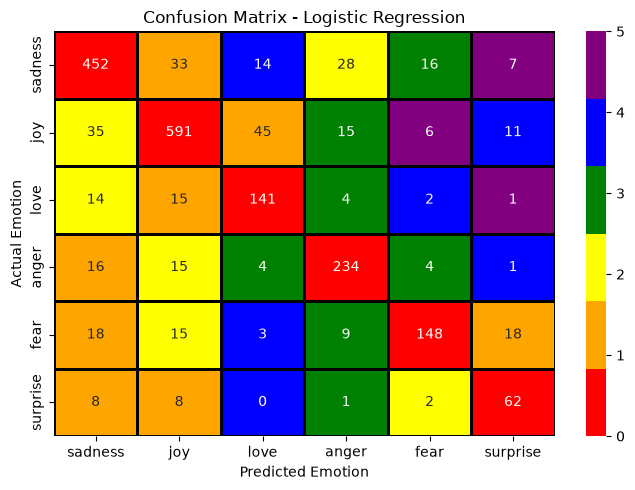

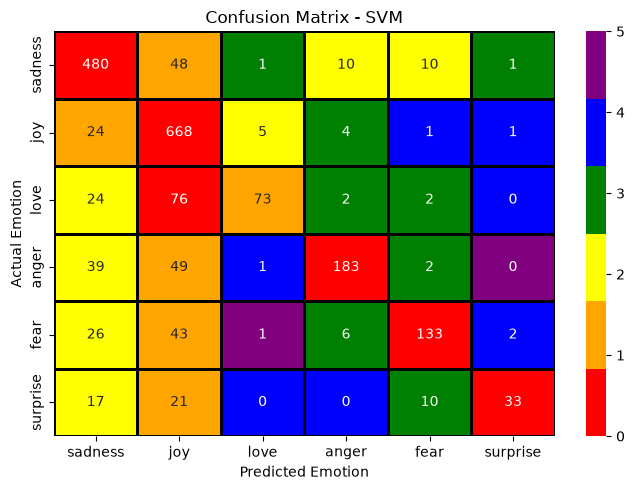

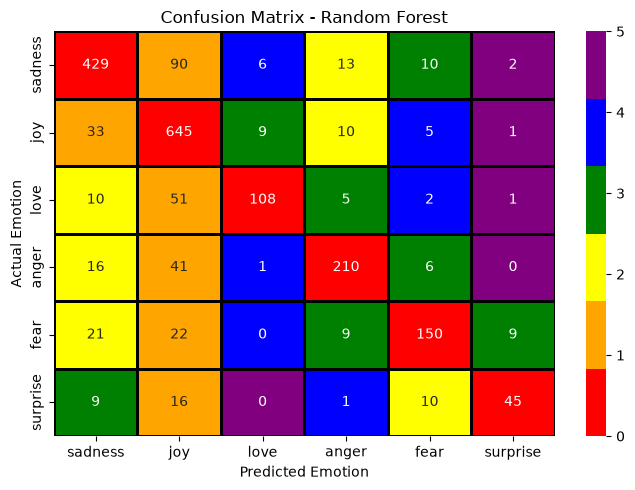

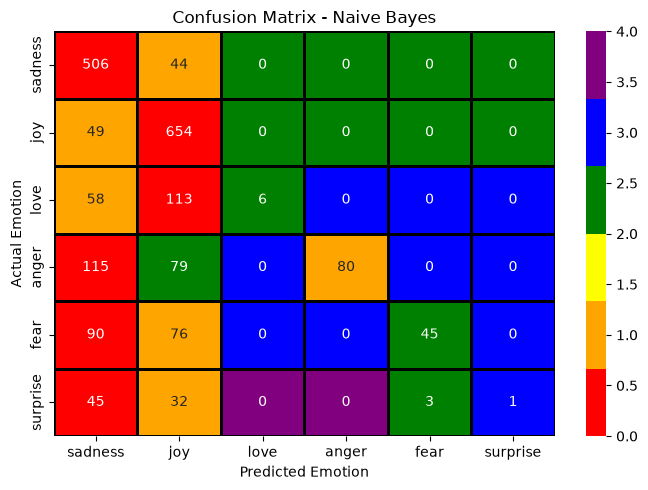

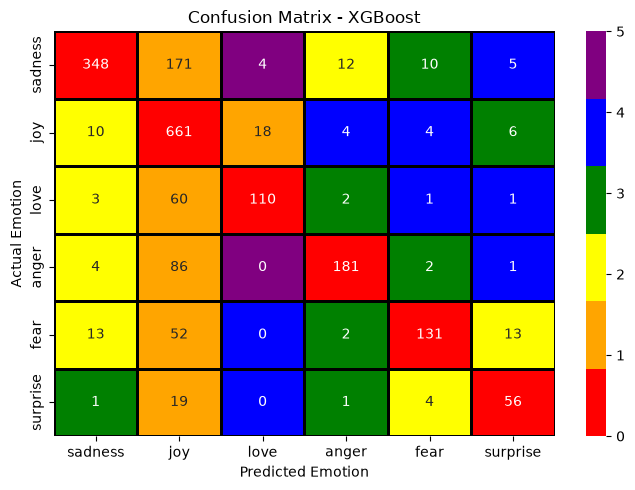

In [108]:
from matplotlib.colors import ListedColormap
for name, y_pred in y_preds.items():

    cm = confusion_matrix(y_val_label,y_pred)

    rank_matrix = np.zeros_like(cm)

    for i, row in enumerate(cm):
        sorted_values = np.sort(np.unique(row))[::-1]

        for rank, value in enumerate(sorted_values):
            rank_matrix[i][row == value] = rank

    colors = [
        "red",       # Highest
        "orange",    # 2nd highest
        "yellow",    # 3rd highest
        "green",     # 4th highest
        "blue",      # 5th highest
        "purple"     # 6th highest
    ]

    cmap = ListedColormap(colors)

    plt.figure(figsize=(7, 5))

    sns.heatmap(
      rank_matrix,
        annot=cm,
        fmt="d",
        cmap=cmap,
        xticklabels=class_name,
        yticklabels=class_name,
        cbar=True,
        linewidths=1,
        linecolor="black"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")

    plt.tight_layout()
    plt.show()

In [102]:
for name, y_pred in y_preds.items():

    cr = classification_report(y_val_label,y_pred,target_names=class_name)
    print(f"classification_report-{name}")
    print(cr)

classification_report-Logistic Regression
              precision    recall  f1-score   support

     sadness       0.83      0.82      0.83       550
         joy       0.87      0.84      0.86       703
        love       0.68      0.80      0.73       177
       anger       0.80      0.85      0.83       274
        fear       0.83      0.70      0.76       211
    surprise       0.62      0.77      0.69        81

    accuracy                           0.82      1996
   macro avg       0.77      0.80      0.78      1996
weighted avg       0.82      0.82      0.82      1996

classification_report-SVM
              precision    recall  f1-score   support

     sadness       0.79      0.87      0.83       550
         joy       0.74      0.95      0.83       703
        love       0.90      0.41      0.57       177
       anger       0.89      0.67      0.76       274
        fear       0.84      0.63      0.72       211
    surprise       0.89      0.41      0.56        81

    accur